# 03 — Model Training and Evaluation

Compares a majority-class baseline with Logistic Regression and Random Forest. Run this notebook only after adding the permitted dataset to `data/`. Results are generated by your run and should not be copied as claims before execution.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path("../data/WA_Fn-UseC_-HR-Employee-Attrition.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}. Read data/README.md and place the permitted CSV there."
    )
df = pd.read_csv(DATA_PATH)
if "Attrition" not in df.columns:
    raise ValueError("Expected target column 'Attrition'. Check data/README.md.")
print(f"Dataset shape: {df.shape}")
display(df.head())


Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
)

df = df.drop_duplicates().copy()
target_map = {"yes": 1, "no": 0, "1": 1, "0": 0, "true": 1, "false": 0}
y = df["Attrition"].astype(str).str.strip().str.lower().map(target_map)
if y.isna().any():
    raise ValueError("Unexpected values in Attrition target; inspect target labels.")
X = df.drop(columns=["Attrition"])
X = X.drop(columns=[c for c in ["EmployeeNumber"] if c in X.columns])
constant_cols = [c for c in X.columns if X[c].nunique(dropna=False) <= 1]
X = X.drop(columns=constant_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y.astype(int), test_size=0.20, random_state=42, stratify=y
)
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_features),
    ("categorical", categorical_pipe, categorical_features)
])

models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42, min_samples_leaf=2
    )
}

results = []
fitted = {}
for name, estimator in models.items():
    pipeline = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    score = None
    if hasattr(pipeline, "predict_proba"):
        try:
            score = pipeline.predict_proba(X_test)[:, 1]
        except Exception:
            score = None
    row = {
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, score) if score is not None and y_test.nunique() == 2 else np.nan
    }
    results.append(row)
    fitted[name] = pipeline
    print(f"\n{name}\n", classification_report(y_test, pred, zero_division=0))

results_df = pd.DataFrame(results).sort_values("f1", ascending=False)
display(results_df.round(3))



Dummy baseline
               precision    recall  f1-score   support

           0       0.84      1.00      0.91       247
           1       0.00      0.00      0.00        47

    accuracy                           0.84       294
   macro avg       0.42      0.50      0.46       294
weighted avg       0.71      0.84      0.77       294


Logistic Regression
               precision    recall  f1-score   support

           0       0.92      0.77      0.84       247
           1       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294


Random Forest
               precision    recall  f1-score   support

           0       0.86      0.97      0.91       247
           1       0.50      0.17      0.25        47

    accuracy                           0.84       294
   macro avg       0.68      0.57      0.58       294
weighted avg       

,model,accuracy,precision,recall,f1,roc_auc
1,Logistic Regression,0.752,0.349,0.638,0.451,0.803
2,Random Forest,0.840,0.500,0.170,0.254,0.798
0,Dummy baseline,0.840,0.000,0.000,0.000,0.500


## Compare models

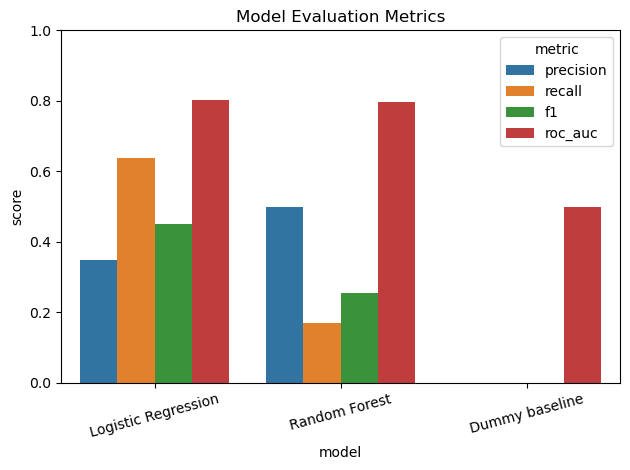

In [4]:
from pathlib import Path
Path("reports").mkdir(exist_ok=True)
results_df.to_csv("reports/model_evaluation_metrics.csv", index=False)

plot_df = results_df.melt(
    id_vars="model", value_vars=["precision", "recall", "f1", "roc_auc"],
    var_name="metric", value_name="score"
)
ax = sns.barplot(data=plot_df, x="model", y="score", hue="metric")
ax.set_ylim(0, 1)
ax.set_title("Model Evaluation Metrics")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig("../reports/model_metrics_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


## Confusion matrix for the best F1 model

Metric choice should reflect the business problem. For an attrition screening use case, recall may matter, but false positives and fairness risks also matter.

Selected by F1 only: Logistic Regression
This selection rule is a teaching example; consider recall, precision, fairness, and costs before choosing a model.


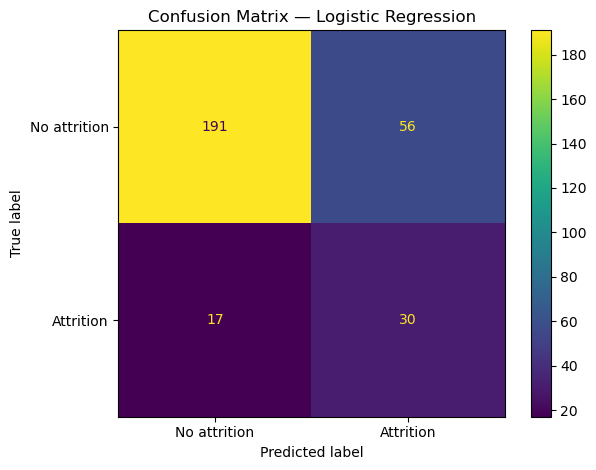

In [5]:
best_name = results_df.iloc[0]["model"]
best_model = fitted[best_name]
best_pred = best_model.predict(X_test)
print("Selected by F1 only:", best_name)
print("This selection rule is a teaching example; consider recall, precision, fairness, and costs before choosing a model.")
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=["No attrition", "Attrition"])
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.savefig("../reports/best_model_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
